In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sacc
from cobaya.model import get_model
import baccoemu
import pyccl as ccl
from cl_like_free import Likelihood
mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Arico2023')

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


In [2]:
fits_file = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
bins = [
    {'name': 'DESI_LRG__0'},
    {'name': 'DESI_LRG__1'},
    {'name': 'DESI_LRG__2'},
    {'name': 'DESI_LRG__3'},
    {'name': 'DESY3wl__0'},
    {'name': 'DESY3wl__1'},
    {'name': 'DESY3wl__2'},
    {'name': 'DESY3wl__3'},
    {'name': 'Planck__kappa18'}
]
twopoints = [
    {'bins': ['DESI_LRG__0', 'DESI_LRG__0']},
    {'bins': ['DESI_LRG__1', 'DESI_LRG__1']},
    {'bins': ['DESI_LRG__2', 'DESI_LRG__2']},
    {'bins': ['DESI_LRG__3', 'DESI_LRG__3']},
    {'bins': ['DESY3wl__0', 'DESY3wl__0']},
    {'bins': ['DESY3wl__0', 'DESY3wl__1']},
    {'bins': ['DESY3wl__0', 'DESY3wl__2']},
    {'bins': ['DESY3wl__0', 'DESY3wl__3']},
    {'bins': ['DESY3wl__1', 'DESY3wl__1']},
    {'bins': ['DESY3wl__1', 'DESY3wl__2']},
    {'bins': ['DESY3wl__1', 'DESY3wl__3']},
    {'bins': ['DESY3wl__2', 'DESY3wl__2']},
    {'bins': ['DESY3wl__2', 'DESY3wl__3']},
    {'bins': ['DESY3wl__3', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__0', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__1', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__2', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__0']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__1']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__2']},
    {'bins': ['DESI_LRG__3', 'DESY3wl__3']},
    {'bins': ['DESI_LRG__0', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__1', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__2', 'Planck__kappa18']},
    {'bins': ['DESI_LRG__3', 'Planck__kappa18']},
    {'bins': ['DESY3wl__0', 'Planck__kappa18']},
    {'bins': ['DESY3wl__1', 'Planck__kappa18']},
    {'bins': ['DESY3wl__2', 'Planck__kappa18']},
    {'bins': ['DESY3wl__3', 'Planck__kappa18']}
]
defaults = {
    'DESI_LRG__0':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__1':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__2':     {'lmin': 20, 'kmax': 0.4},
    'DESI_LRG__3':     {'lmin': 20, 'kmax': 0.4},
    'DESY3wl__0':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__1':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__2':      {'lmin': 20, 'lmax': 4500},
    'DESY3wl__3':      {'lmin': 20, 'lmax': 4500},
    'Planck__kappa18': {'lmin': 20, 'lmax': 4500}
}
ia_parameters = {
    'ia_model': 'IADESY1_PerSurvey',
    'input_params_prefix': 'ia'

    # 'ia_model': 'IANone'
}
magnification_bias_parameters = {
    'use_magnification_bias': True,
    'input_params_prefix': 'mag'
}
nz_uncertainty_parameters = {
    'nz_model': 'NzShift',
    'input_params_prefix': 'nz'
}
shape_model_parameters = {
    'shape_model': 'ShapeMultiplicative',
    'input_params_prefix': 'shape'
}

print('Number of cross-correlations: ', len(twopoints))
print('')
sampling_params = {
    'Omega_cdm': 0.31 - 0.05 - 0.06/93.14/0.7**2,
    'Omega_b': 0.05,
    'h': 0.7,
    'n_s': 0.96,
    'sigma8': 0.81,
    'w0': -1.0,
    'wa': 0.0,
    'M_nu': 0.0,

    'bias_DESI_LRG__0_b1': 0.804122,
    'bias_DESI_LRG__0_b2': -0.107144,
    'bias_DESI_LRG__0_bs': -1.50533,
    'bias_DESI_LRG__0_blap': 0.467558,
    'bias_DESI_LRG__1_b1': 0.975929,
    'bias_DESI_LRG__1_b2': 0.0133623,
    'bias_DESI_LRG__1_bs': -1.57116,
    'bias_DESI_LRG__1_blap': 0.679513,
    'bias_DESI_LRG__2_b1': 1.15545,
    'bias_DESI_LRG__2_b2': 0.887713,
    'bias_DESI_LRG__2_bs': -2.43004,
    'bias_DESI_LRG__2_blap': 3.46969,
    'bias_DESI_LRG__3_b1': 1.24726,
    'bias_DESI_LRG__3_b2': 0.920292,
    'bias_DESI_LRG__3_bs': -0.020529,
    'bias_DESI_LRG__3_blap': 2.09777,

    'ia_DESY3wl_A_IA': 0.139753,
    'ia_DESY3wl_eta_IA': 0.00534004,

    'mag_DESI_LRG__0_s': 0.972,
    'mag_DESI_LRG__1_s': 1.044,
    'mag_DESI_LRG__2_s': 0.974,
    'mag_DESI_LRG__3_s': 0.988,

    'nz_DESY3wl__0_dz': 0.00487793,
    'nz_DESY3wl__1_dz': -0.00361057,
    'nz_DESY3wl__2_dz': -0.00472961,
    'nz_DESY3wl__3_dz': 0.00365068,

    'shape_DESY3wl__0_m': -0.0062983,
    'shape_DESY3wl__1_m': -0.01969,
    'shape_DESY3wl__2_m': -0.0265481,
    'shape_DESY3wl__3_m': -0.0354792,

    'nz_DESI_LRG__0_dz': 0,
    'nz_DESI_LRG__1_dz': 0,
    'nz_DESI_LRG__2_dz': 0,
    'nz_DESI_LRG__3_dz': 0,

    'M_c': 13.5166,
    'eta': -0.2993,
    'beta': -0.199556,
    'M1_z0_cen': 11.6905,
    'theta_inn': -0.833179,
    'theta_out': 0.227195,
    'M_inn': 11.8591
}

print('Number of sampling parameters: ', len(sampling_params))

myll = Likelihood(fits_file=fits_file, bins=bins, twopoints=twopoints, defaults=defaults, sample_type='convolve', bias_input_name='bias', use_baryons=True, ia_parameters=ia_parameters, magnification_bias_parameters=magnification_bias_parameters, nz_uncertainty_parameters=nz_uncertainty_parameters, shape_model_parameters=shape_model_parameters, debug=True)
theory_vector = myll.get_theory_perbin(sampling_params)

Number of cross-correlations:  38

Number of sampling parameters:  49
Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emul

In [3]:
this_chi2 = myll.get_chi2(sampling_params)

WARNIG: in debug mode, NOT clearing cache for heft_calculator and mpk_calculator


In [4]:
paramfile = 'compare_cl_like_files/test_5x2point.yml'
model = get_model(paramfile)
pars = {
    'sigma8': 0.81,
    'Omega_m': 0.31,
    'Omega_b': 0.05,
    'h': 0.7,
    'n_s': 0.96,
    'm_nu': 0.06,
    'bias_DESI_LRG__0_b1': 0.804122,
    'bias_DESI_LRG__0_b2': -0.107144,
    'bias_DESI_LRG__0_bs': -1.50533,
    'bias_DESI_LRG__0_bk2': 0.467558,
    'bias_DESI_LRG__1_b1': 0.975929,
    'bias_DESI_LRG__1_b2': 0.0133623,
    'bias_DESI_LRG__1_bs': -1.57116,
    'bias_DESI_LRG__1_bk2': 0.679513,
    'bias_DESI_LRG__2_b1': 1.15545,
    'bias_DESI_LRG__2_b2': 0.887713,
    'bias_DESI_LRG__2_bs': -2.43004,
    'bias_DESI_LRG__2_bk2': 3.46969,
    'bias_DESI_LRG__3_b1': 1.24726,
    'bias_DESI_LRG__3_b2': 0.920292,
    'bias_DESI_LRG__3_bs': -0.020529,
    'bias_DESI_LRG__3_bk2': 2.09777,
    'bias_DESY3wl_A_IA': 0.139753,
    'limber_DESY3wl_eta_IA': 0.00534004,
    'bias_DESI_LRG__0_s': 0.972,
    'bias_DESI_LRG__1_s': 1.044,
    'bias_DESI_LRG__2_s': 0.974,
    'bias_DESI_LRG__3_s': 0.988,
    'limber_DESY3wl__0_dz': 0.00487793,
    'limber_DESY3wl__1_dz': -0.00361057,
    'limber_DESY3wl__2_dz': -0.00472961,
    'limber_DESY3wl__3_dz': 0.00365068,
    'bias_DESY3wl__0_m': -0.0062983,
    'bias_DESY3wl__1_m': -0.01969,
    'bias_DESY3wl__2_m': -0.0265481,
    'bias_DESY3wl__3_m': -0.0354792,
    'M_c': 13.5166,
    'eta': -0.2993,
    'beta': -0.199556,
    'M1_z0_cen': 11.6905,
    'theta_inn': -0.833179,
    'theta_out': 0.227195,
    'M_inn': 11.8591

}
logp = model.logposterior(pars)
print(logp)
ll = model.likelihood['cl_like.ClLike']
allbins = ll.twopoints
cls_th = ll.provider.get_cl_theory()

[model] *WARNING* Ignored blocks/options: ['sampler', 'force', 'output']
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Bias Model is HEFT
Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
L

E1022 16:56:11.989070   44886 xtile_compiler.cc:399] Fusion: gemm_fusion_dot_general.1 = f32[20,46]{1,0} fusion(a.1, b.1), kind=kCustom, calls=gemm_fusion_dot_general.1_computation.clone, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["64","128"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E1022 16:56:11.989150   44886 xtile_compiler.cc:401] Computation: gemm_fusion_dot_general.1_computation.clone {
  parameter_0 = f32[20,400]{1,0} parameter(0)
  parameter_1 = f32[400,46]{1,0} parameter(1)
  ROOT dot_general.0 = f32[20,46]{1,0} dot(parameter_0, parameter_1), lhs_contracting_dims={1}, rhs_contracting_dims={0}, backend_config={"sizes":["64"]}
}
E1022 16:56:11.991773   44879 xtile_compiler.cc:399

LogPosterior(logpost=np.float64(-597.1126084272374), logpriors=[np.float64(-3.637979241757975)], loglikes=array([-593.47462919]), derived=[np.float64(0.8233893368267531)], finite=False)


In [7]:
import pickle
with open('compare_cl_like_files/cls_th_cl_like_5x2pt.pkl', 'rb') as f:
    saved_cls_th = pickle.load(f)
if not np.allclose(cls_th, saved_cls_th):
    print('cls_th and saved_cls_th are not equal')
else:
    print('cls_th and saved_cls_th are equal')

cls_th and saved_cls_th are equal


In [8]:
mynames = {
    'DESI_LRG__0': r'$\delta_{\rm g}$0',
    'DESI_LRG__1': r'$\delta_{\rm g}$1',
    'DESI_LRG__2': r'$\delta_{\rm g}$2',
    'DESI_LRG__3': r'$\delta_{\rm g}$3',
    'Planck__kappa18': r'$\kappa$',
    'DESY3wl__0': r'$\gamma$0',
    'DESY3wl__1': r'$\gamma$1',
    'DESY3wl__2': r'$\gamma$2',
    'DESY3wl__3': r'$\gamma$3'
}

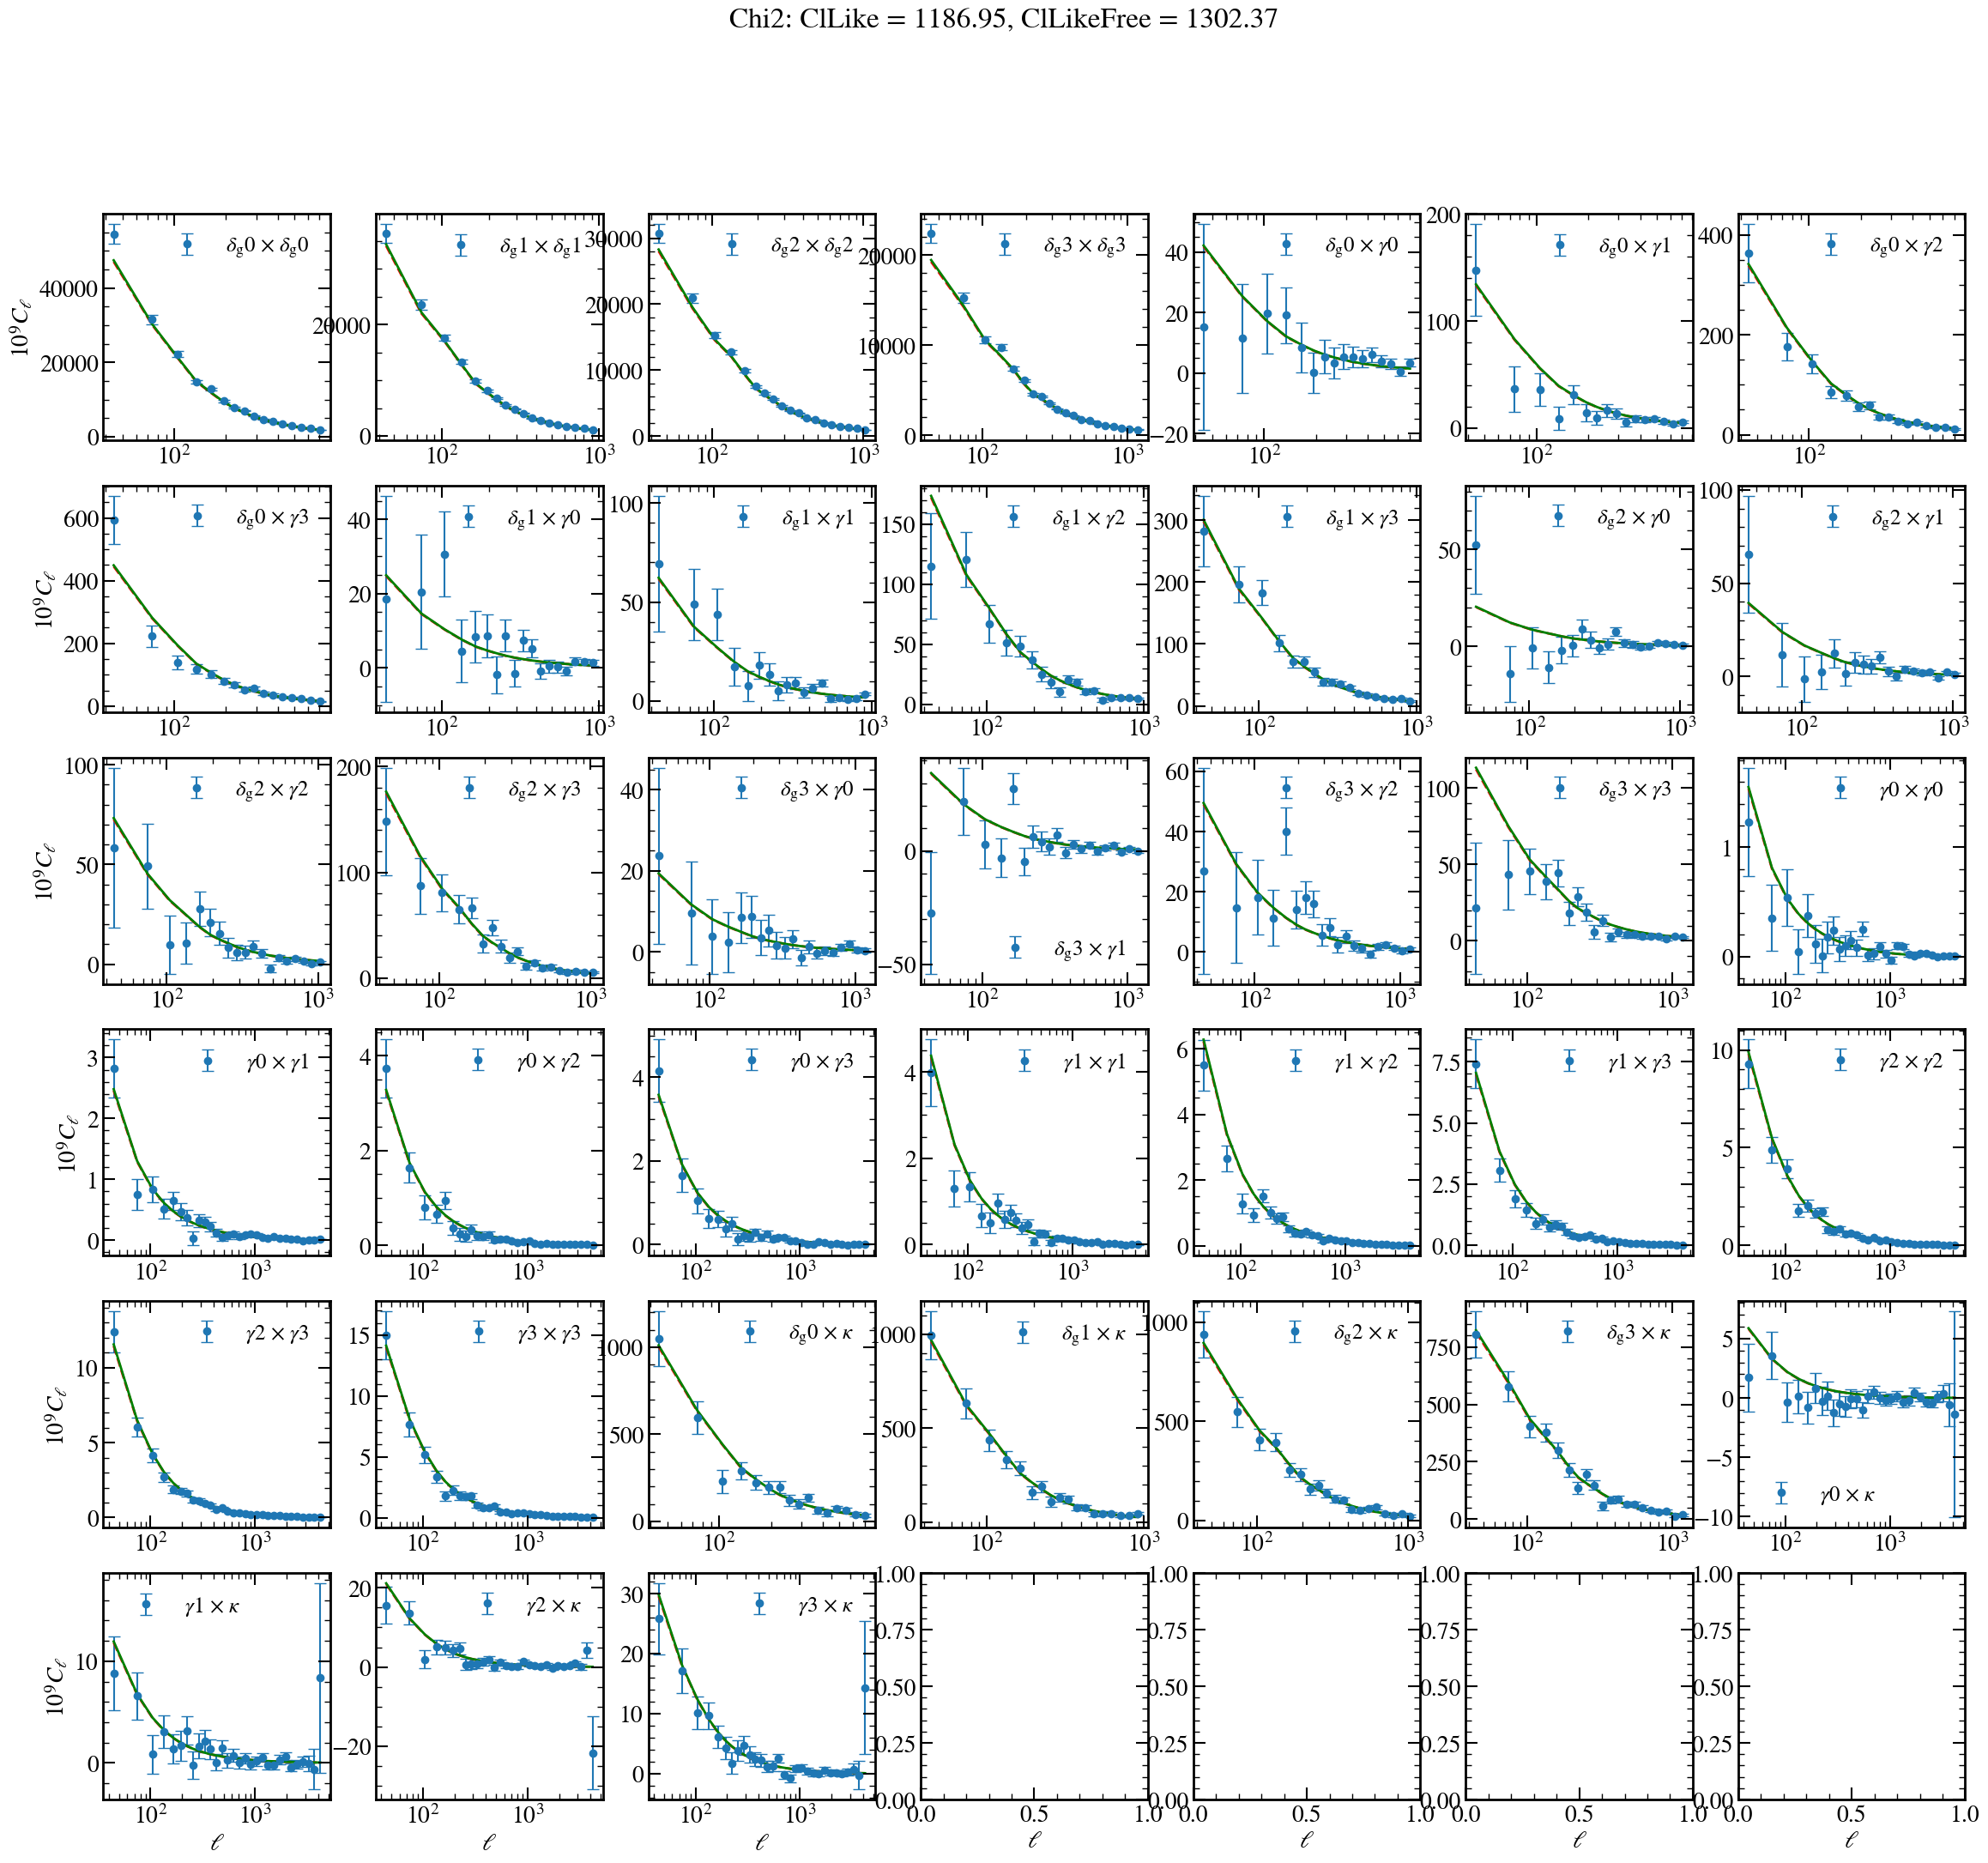

In [9]:
N_subplots = len(ll.cl_meta)
N_rows = int(np.sqrt(N_subplots))
N_cols = N_subplots // N_rows + (N_subplots % N_rows > 0)
Row_hight = 4
Column_width = 4

fig, ax = plt.subplots(N_rows, N_cols, figsize=(N_cols * Column_width, N_rows * Row_hight))

i_start = 0

for ii, clm in enumerate(ll.cl_meta):
    bin1, bin2 = clm['bin_1'], clm['bin_2']
    l_eff, cl, cov = clm['l_eff'], clm['cl'], clm['cov']

    twopt_name = '%s_%s'%(bin1, bin2)
    if twopt_name not in theory_vector:
        twoopt_name = '%s_%s'%(bin2, bin1)
        if twoopt_name not in theory_vector:
            raise ValueError('Theory vector for %s or %s not found'%(twopt_name, twoopt_name))
        twopt_name = twoopt_name
    this_cl_theory = theory_vector[twopt_name]

    inds = ll.cl_meta[ii]['inds']
    cllike_theory = cls_th[inds]

    ax[ii // N_cols, ii % N_cols].errorbar(l_eff, 1e9 *cl, yerr=1e9 * np.sqrt(np.diag(cov)), fmt='o', capsize=5, label=r'%s $\times$ %s'%(mynames[bin1], mynames[bin2]))
    ax[ii // N_cols, ii % N_cols].plot(l_eff, 1e9 * this_cl_theory, 'r--', linewidth=2)
    ax[ii // N_cols, ii % N_cols].plot(l_eff, 1e9 * cllike_theory, 'g-', linewidth=2)
    ax[ii // N_cols, ii % N_cols].legend()
    ax[ii // N_cols, ii % N_cols].set_xscale('log')

for ii in range(N_cols):
    ax[N_rows-1, ii].set_xlabel('$\ell$')
for ii in range(N_rows):
    ax[ii, 0].set_ylabel('$10^9 C_\ell$')

cl_like_chi2, cl_like_free_chi2 = -2*logp.loglike, this_chi2
fig.suptitle('Chi2: ClLike = %.2f, ClLikeFree = %.2f'%(cl_like_chi2, cl_like_free_chi2))

plt.show()

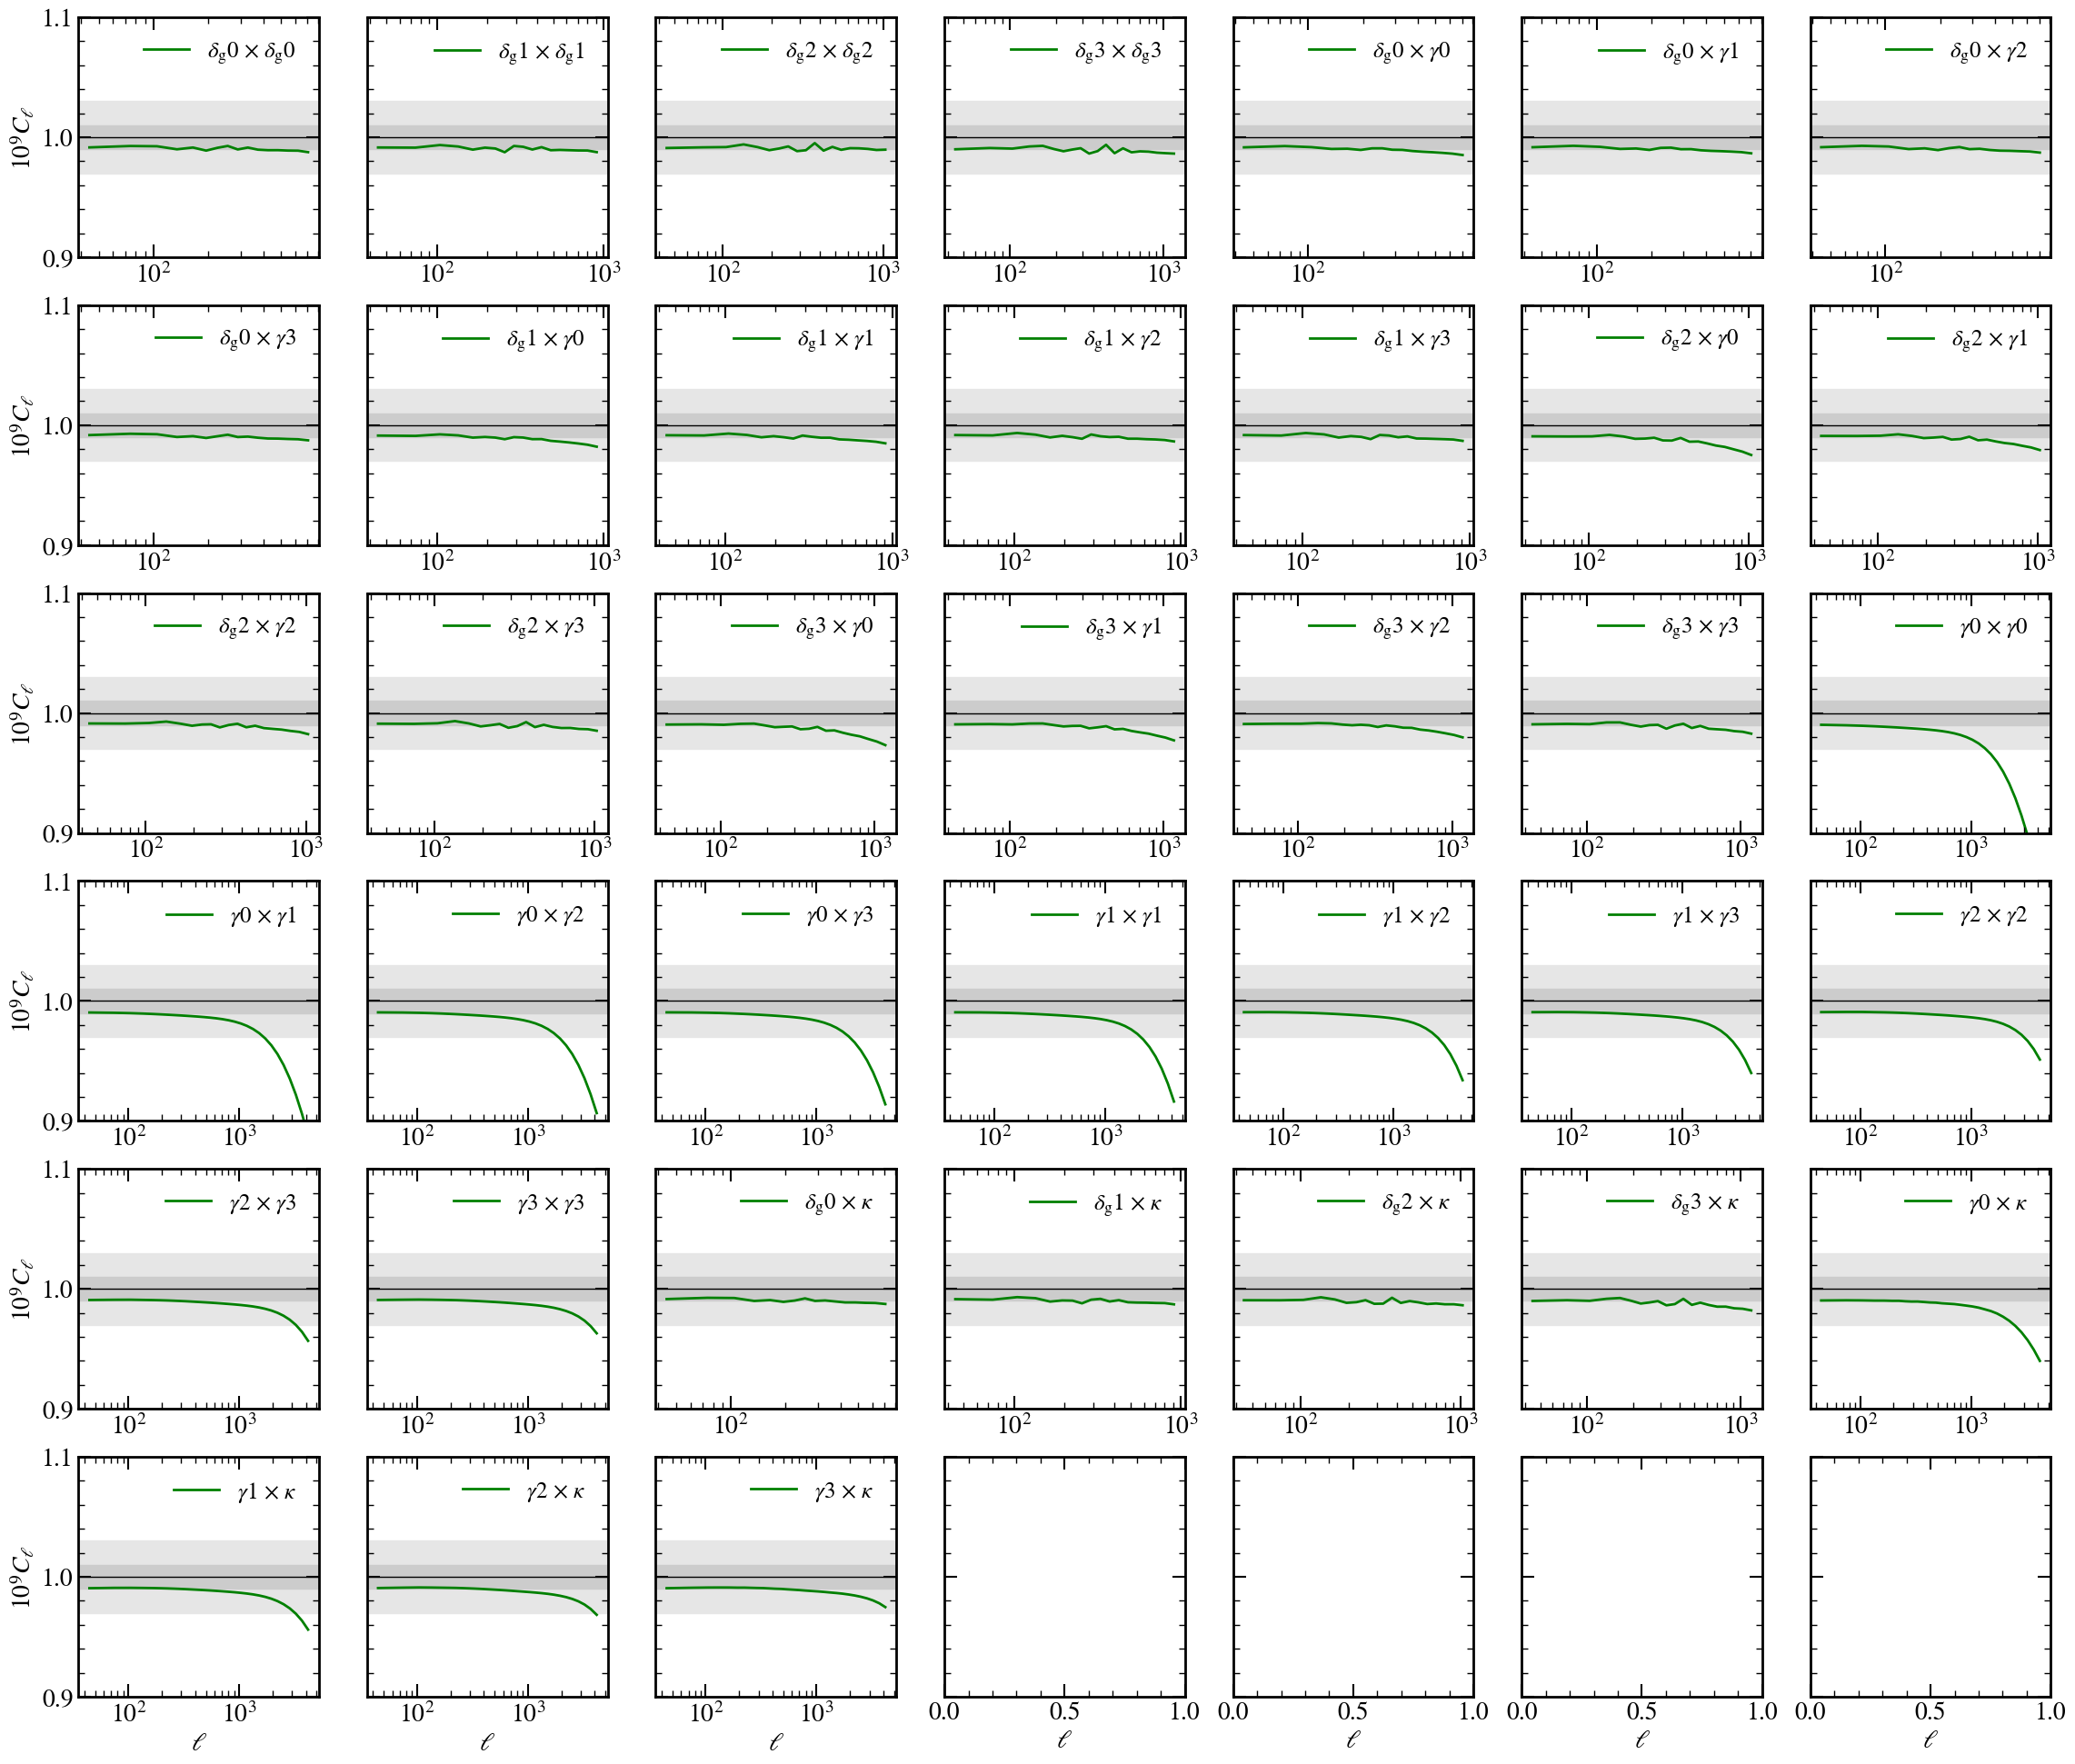

In [10]:
N_subplots = len(ll.cl_meta)
N_rows = int(np.sqrt(N_subplots))
N_cols = N_subplots // N_rows + (N_subplots % N_rows > 0)
Row_hight = 4
Column_width = 4

fig, ax = plt.subplots(N_rows, N_cols, sharey=True, figsize=(N_cols * Column_width, N_rows * Row_hight))

i_start = 0

for ii, clm in enumerate(ll.cl_meta):
    bin1, bin2 = clm['bin_1'], clm['bin_2']
    l_eff, cl, cov = clm['l_eff'], clm['cl'], clm['cov']

    twopt_name = '%s_%s'%(bin1, bin2)
    if twopt_name not in theory_vector:
        twoopt_name = '%s_%s'%(bin2, bin1)
        if twoopt_name not in theory_vector:
            raise ValueError('Theory vector for %s or %s not found'%(twopt_name, twoopt_name))
        twopt_name = twoopt_name
    this_cl_theory = theory_vector[twopt_name]

    inds = ll.cl_meta[ii]['inds']
    cllike_theory = cls_th[inds]

    ax[ii // N_cols, ii % N_cols].axhspan(0.97, 1.03, color='0.9')
    ax[ii // N_cols, ii % N_cols].axhspan(0.99, 1.01, color='0.8')
    ax[ii // N_cols, ii % N_cols].axhline(1.0, color='k', linewidth=1)
    ax[ii // N_cols, ii % N_cols].plot(l_eff, this_cl_theory / cllike_theory, 'g-', linewidth=2, label=r'%s $\times$ %s'%(mynames[bin1], mynames[bin2]))
    ax[ii // N_cols, ii % N_cols].legend()
    ax[ii // N_cols, ii % N_cols].set_xscale('log')
    ax[ii // N_cols, ii % N_cols].set_ylim(0.9, 1.1)

for ii in range(N_cols):
    ax[N_rows-1, ii].set_xlabel('$\ell$')
for ii in range(N_rows):
    ax[ii, 0].set_ylabel('$10^9 C_\ell$')

plt.show()